In [6]:
import pandas as pd
import numpy as np
from simulation import generate_catalog
from inversion import round_half_up
from shapely.geometry import Polygon
import datetime as dt
from mc_b_est import estimate_beta_tinti
import matplotlib.pyplot as plt

In [30]:
fn_store = 'synthetic_catalog_mc_var.csv'
shape_coords = np.load("california_shape.npy")
caliregion = Polygon(shape_coords)
burn_start = dt.datetime(1871, 1, 1)
primary_start = dt.datetime(1971, 1, 1)
end = dt.datetime(2022, 1, 1)

delta_m = 0.1
mc = 2.5
beta = np.log(10)

parameters = {
    'log10_mu': -7.3,
    'log10_k0': -2.5,
    'a': 1.7,
    'log10_c': -2.95,
    'omega': -0.03,
    'log10_tau': 4.0,
    'log10_d': -0.35,
    'gamma': 1.2,
    'rho': 0.5
}

#np.random.seed(557755)

synthetic = generate_catalog(
    polygon=caliregion,
    timewindow_start=burn_start,
    timewindow_end=end,
    parameters=parameters,
    mc=mc,
    beta_main=beta,
    delta_m=delta_m
)

synthetic.magnitude = round_half_up(synthetic.magnitude, 1)
synthetic.index.name = 'id'


generating background events..
  number of background events needed: 2603
  generating 5299 to throw away those outside the polygon
  number of background events: 2603

  branching ratio: 0.9125131011613676
  expected total number of events (if time were infinite): 29753.026276553424


simulating aftershocks of generation 0 ..
  number of events with aftershocks: 1405
  number of generated aftershocks: 2219


simulating aftershocks of generation 1 ..
  number of events with aftershocks: 1151
  number of generated aftershocks: 2020


simulating aftershocks of generation 2 ..
  number of events with aftershocks: 1084
  number of generated aftershocks: 1771


simulating aftershocks of generation 3 ..
  number of events with aftershocks: 957
  number of generated aftershocks: 1615


simulating aftershocks of generation 4 ..
  number of events with aftershocks: 862
  number of generated aftershocks: 1462


simulating aftershocks of generation 5 ..
  number of events with aftershocks: 803
  

In [31]:
synthetic = synthetic[["latitude", "longitude", "time", "magnitude"]].query("time>=@primary_start")
synthetic.sort_values(by="time", inplace=True)

In [32]:
#synthetic = pd.read_csv("synthetic_catalog.csv", index_col=0, parse_dates=["time"])

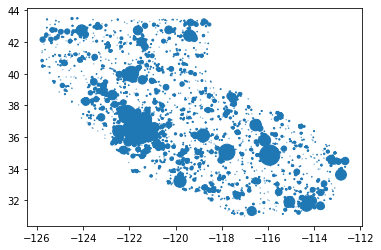

In [33]:
plt.scatter(synthetic.longitude, synthetic.latitude, (synthetic.magnitude-2)**4)

In [34]:
synthetic["mc_current"] = np.where(
    synthetic.time <= dt.datetime(1981, 1, 1),
    3.0,
    np.where(
        synthetic.time <= dt.datetime(2010, 1, 1),
        2.7,
        2.5
    )
)
synthetic["mc_current"] = np.where(
    synthetic.latitude >= 37,
    synthetic["mc_current"],
    synthetic["mc_current"] + 0.1
)
synthetic["mc_current"] = round_half_up(synthetic["mc_current"], 1)

In [35]:
#synthetic.mc_current += 1.1
#synthetic["mc_current"] = round_half_up(synthetic["mc_current"], 1)

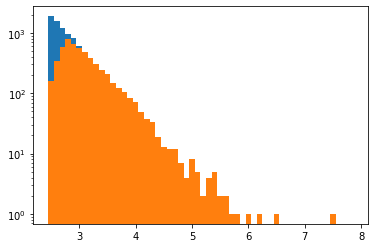

In [36]:
plt.hist(
    synthetic.magnitude, bins = np.arange(2.45, 7.9, 0.1)
)
plt.hist(
    synthetic.query("magnitude >= mc_current").magnitude, bins = np.arange(2.45, 7.9, 0.1)
)
plt.yscale("log")

In [37]:
synthetic.query("magnitude >= mc_current")

,latitude,longitude,time,magnitude,mc_current
id,,,,,
1755,34.197116,-114.926648,1971-01-03 20:43:01.075871000,3.4,3.1
4124,34.191703,-114.961450,1971-01-04 16:05:24.073871000,3.2,3.1
1756,32.133243,-118.571262,1971-01-20 14:15:26.470704000,3.2,3.1
17900,36.252223,-121.869863,1971-02-02 08:26:55.315181400,3.1,3.1
21984,42.735379,-123.043198,1971-03-01 15:25:22.786888997,3.1,3.0
...,...,...,...,...,...
2603,33.101923,-116.124673,2021-12-26 07:56:23.283986000,2.6,2.6
23517,37.685527,-121.232029,2021-12-28 15:04:26.093317799,2.7,2.5
22879,34.857792,-115.871476,2021-12-29 06:39:39.356238799,3.7,2.6


In [38]:
estimate_beta_tinti(synthetic.magnitude, mc=2.5, delta_m=0.1), estimate_beta_tinti(synthetic.magnitude - 2.5, mc=0, delta_m=0.1)

(2.2963603812736046, 2.2963603812736046)

In [39]:
estimate_beta_tinti(
    synthetic.query("magnitude>=mc_current").magnitude - synthetic.query("magnitude>=mc_current").mc_current,
    mc=0, delta_m=0.1
)

2.335004805060216

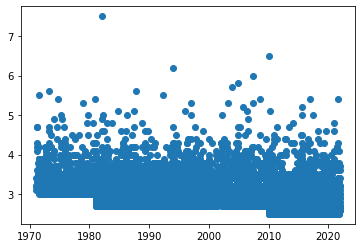

In [40]:
import matplotlib.pyplot as plt
plt.scatter(
    synthetic.query("magnitude >= mc_current").time,
    synthetic.query("magnitude >= mc_current").magnitude
)

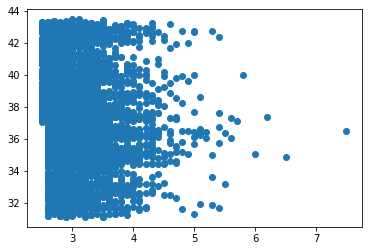

In [41]:
import matplotlib.pyplot as plt
plt.scatter(
    synthetic.query("magnitude >= mc_current").magnitude,
    synthetic.query("magnitude >= mc_current").latitude,
)

In [42]:
synthetic.query("magnitude>=mc_current").to_csv("synthetic_catalog_mc_var.csv")

In [377]:
from inversion import branching_ratio, parameter_dict2array

parameters = {
    'log10_mu': -6.5,
    'log10_k0': -2.5,
    'a': 2.7,
    'log10_c': -2.95,
    'omega': -0.03,
    'log10_tau': 4.0,
    'log10_d': -0.35,
    'gamma': 1.2,
    'rho': 0.5
}

pars = {   'a': 2.0145059016445637,
    'gamma': 1.5497113990283564,
    'log10_c': -6.9662471073943895,
    'log10_d': -0.35,#0.40739112151336787,
    'log10_k0': -2.3903750533674026,
    'log10_mu': -6.6863306273710785,
    'log10_tau': 3.848754594194267,
    'omega': -0.01980191984101351,
    'rho': 0.6875491927091433}

branching_ratio(parameter_dict2array(pars), beta=np.log(10))

1.2534492933206445

In [371]:
pars["a"] - pars["rho"]*pars["gamma"]

0.9490030803104601

In [339]:
synthetic["magnitude"]

id
1065     3.8
1066     4.2
1067     3.8
1068     3.6
1069     3.6
        ... 
10541    3.7
10542    3.8
10563    4.4
10564    4.6
10582    3.6
Name: magnitude, Length: 4454, dtype: float64

In [340]:
print("store catalog..")
synthetic[["latitude", "longitude", "time", "magnitude"]].query("time>=@primary_start").to_csv(fn_store)
print("\nDONE!")

store catalog..

DONE!


In [427]:
from pynverse import inversefunc

In [502]:
upper_gamma_ext(0.03, 1000000)

0.0

In [513]:
from scipy.special import gamma as gamma_func

def upper_gamma_ext(a, x):
    if a > 0:
        return gammaincc(a, x) * gamma_func(a)
    elif a == 0:
        return exp1(x)
    else:
        return (upper_gamma_ext(a + 1, x) - np.power(x, a)*np.exp(-x)) / a

/Users/leila/anaconda3/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [514]:
def inverse_upper_gamma_ext(a, y):
	# TODO: find a more elegant way to do this
	if a > 0:
		return gammainccinv(a, y/gamma_func(a))
	else:
		from pynverse import inversefunc
		import warnings
		from scipy.optimize import minimize

		uge = (lambda x: upper_gamma_ext(a, x))

		# numerical inverse
		def num_inv(a, y):
			def diff(x, xhat):
				xt = upper_gamma_ext(a, x)
				return (xt - xhat)**2
			x = np.zeros(len(y))
			for idx, y_value in enumerate(y):
				res = minimize(diff, 1.0, args=(y_value), method='Nelder-Mead', tol=1e-6)
				x[idx] = res.x[0]

			return x

		warnings.filterwarnings("ignore")
		result = inversefunc(uge, y)
		warnings.filterwarnings("default")

		# where inversefunc was unable to calculate a result, calculate numerical approximation
		nan_idxs = np.argwhere(np.isnan(result)).flatten()
		if len(nan_idxs) > 0:
			num_res = num_inv(a, y[nan_idxs])
			result[nan_idxs] = num_res
		return result


def simulate_aftershock_time_tapered_1(log10_c, omega, log10_tau, size=1):
	# time delay in days
	c = np.power(10, log10_c)
	tau = np.power(10, log10_tau)
	y = np.random.uniform(size=size)

	return inverse_upper_gamma_ext(-omega, (1 - y) * upper_gamma_ext(-omega, c / tau)) * tau - c

def time_sf(t, omega, c, tau):
	return upper_gamma_ext(-omega, (c + t) / tau) / upper_gamma_ext(-omega, c / tau)

def simulate_aftershock_time_tapered_2(log10_c, omega, log10_tau, size=1):
	# time delay in days
	c = np.power(10, log10_c)
	tau = np.power(10, log10_tau)
	y = np.random.uniform(size=size)

	if omega < 0:
		return gammainccinv(-omega, (1 - y) * gammaincc(-omega, c / tau)) * tau - c
	return inversefunc(time_sf, args=(omega, c, tau), y_values=1 - y)


In [519]:
import sys
sys.path.append("../../forecasting/python/")
from etas_em_tapered_omori import expected_aftershocks as expected_aftershocks_omori_tau, upper_gamma_ext
from scipy.special import gammaincc, gammainccinv


log10_c = parameters["log10_c"]
log10_tau = parameters["log10_tau"]

c = np.power(10, log10_c)
tau = np.power(10, log10_tau)
y = np.random.uniform(size=1000)



In [520]:
parameters["omega"]

-0.03

In [527]:
omega = 0.03

simulate_aftershock_time_tapered_1(log10_c, omega, log10_tau, size=1000)

/Users/leila/anaconda3/lib/python3.8/site-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


array([1.84007086e-02, 4.25174270e+01, 2.04270872e+01, 3.14808587e+02,
       2.88994746e-03, 1.70157615e-03, 1.55790174e+00, 7.46986844e+00,
       6.98886066e-02, 2.33435508e+00, 2.53228066e-02, 1.82276205e-01,
       3.70361302e+03, 3.94498369e+00, 5.30686051e-04, 9.44654918e-04,
       1.17262644e-01, 1.52784727e+03, 7.28881385e-01, 5.91534829e+00,
       1.40239403e+03, 1.11612324e-03, 2.43817883e-01, 5.37545647e-02,
       1.52791023e-02, 1.91511324e+03, 5.48396197e+01, 1.35567202e-01,
       9.04955111e+02, 4.97921319e+00, 2.31896640e+01, 7.20239977e-02,
       2.44040608e-04, 6.44759493e+03, 3.61096170e-02, 4.41383363e-03,
       2.78822425e-02, 7.88972827e+01, 2.22336601e+01, 3.93749034e+00,
       2.87695041e-01, 4.05713017e-02, 6.08094553e-01, 1.40497148e+03,
       8.88278088e-04, 6.96908252e+00, 6.72199001e-01, 1.33000476e+01,
       2.45734165e+00, 4.80906143e+02, 1.77713486e+03, 5.37232141e-02,
       6.05595185e-03, 1.87486204e+01, 3.12053259e-02, 2.88749030e+01,
      

In [517]:
omega = -0.03
y = 0.9
# 1
print(inverse_upper_gamma_ext(-omega, (1 - y) * upper_gamma_ext(-omega, c / tau)) * tau - c)
# 2
print(gammainccinv(-omega, (1 - y) * gammaincc(-omega, c / tau)) * tau - c)

1956.5483258897686
12.16072083408677 0.37092333217766604
1956.5483258897693


(array([825.,  58.,  34.,  15.,  10.,  12.,   8.,   5.,   4.,   3.,   1.,
          4.,   4.,   0.,   1.,   3.,   2.,   1.,   1.,   0.,   1.,   0.,
          0.,   0.,   1.,   1.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,
          0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          1.,   0.,   0.,   1.,   1.,   1.]),
 array([5.70046596e-06, 7.61142978e+02, 1.52228595e+03, 2.28342892e+03,
        3.04457189e+03, 3.80571487e+03, 4.56685784e+03, 5.32800081e+03,
        6.08914378e+03, 6.85028676e+03, 7.61142973e+03, 8.37257270e+03,
        9.13371567e+03, 9.89485864e+03, 1.06560016e+04, 1.14171446e+04,
        1.21782876e+04, 1.29394305e+04, 1.37005735e+04, 1.44617165e+04,
        1.52228595e+04, 1.59840024e+04, 1.67451454e+04, 1.75062884e+04,
        1.82674313e+04, 1.90285743e+04, 1.97897173e+04, 2.05508603e+04,
        2.13120032e+04, 2.20731462e+04, 2.28342892e+04, 2.35954321e+04,
        2.43565751e+04, 2.51177181e+04, 2.58788611e+04, 2.66400040e+04,
        2.

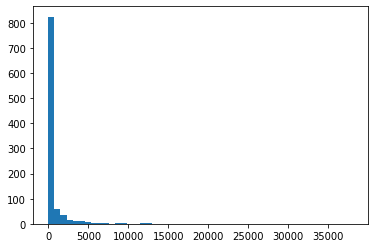

In [411]:
plt.hist(
    simulate_aftershock_time_tapered(log10_c, omega, log10_tau, size=1000),
    bins=50
)